# Figure 2e
Number of vertices against the temperature and the fixation location probability at $r=2$, for every vertex of every connected undirected graph with $N=7$ vertices. The black curve connects the average probability at each distinct temperature.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D

from fixloc import style as S

d = json.load(open('data.json'))
th, p = np.array(d['theta'], float), np.array(d['P_last'], float)

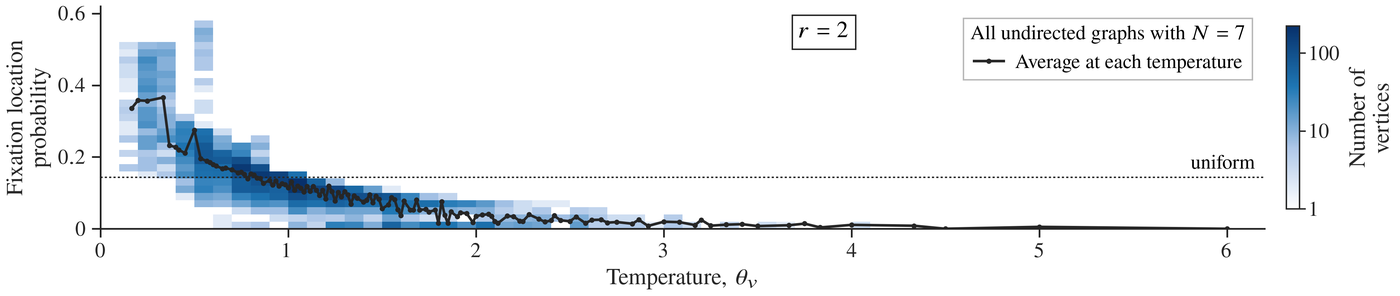

In [2]:
fig = plt.figure(figsize=(7.0, 4.75))
ax = fig.add_axes([0.1, 0.075, 0.8, 0.225])
xe = np.round(np.arange(0, 6.2001, 0.1), 10)
ye = np.round(np.arange(0, 0.6201, 0.02), 10)
H, _, _ = np.histogram2d(th, p, bins=[xe, ye])
assert int(H.sum()) == th.size
cm = LinearSegmentedColormap.from_list('cnt', [(1, 1, 1), S.LBLUE, S.BLUE, (0.03, 0.19, 0.42)])
Hm = np.ma.masked_equal(H.T, 0)
ax.pcolormesh(xe, ye, Hm, cmap=cm, norm=LogNorm(vmin=1, vmax=float(H.max())), shading='flat', rasterized=True, zorder=1)
tu, inv, cnt = np.unique(np.round(th, 9), return_inverse=True, return_counts=True)
avg = np.bincount(inv, weights=p) / cnt
ax.plot(tu, avg, color=S.INK, lw=0.9, marker='o', ms=1.8, mfc=S.INK, mec='none', zorder=3)
ax.axhline(1 / d['N'], color=S.INK, lw=0.5, ls=(0, (1.5, 1.5)), zorder=2)
ax.text(6.15, 1 / d['N'] + 0.012, 'uniform', ha='right', va='bottom', fontsize=7)
ax.set_xlim(0, 6.2)
ax.set_ylim(0, 0.62)
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax.set_yticklabels([r'$0$', r'$0.2$', r'$0.4$', r'$0.6$'])
ax.set_xticks(range(7))
ax.set_xticklabels([r'$%d$' % k for k in range(7)])
ax.set_xlabel(r'Temperature, $\theta_v$')
ax.set_ylabel('Fixation location\nprobability')
hs = [
  Line2D([], [], color=S.INK, lw=0.9, marker='o', ms=1.8, mfc=S.INK, mec='none', label='Average at each temperature')
]
title = r'All undirected graphs with $N=%d$' % d['N']
S.legend(ax, handles=hs, title=title, loc='upper right', handlelength=1.6, borderpad=0.35, title_fontsize=7)
S.boxed(ax, 0.6, 0.93, r'$r=%g$' % d['r'], transform=ax.transAxes, ha='left', va='top')
cax = fig.add_axes([0.915, 0.095, 0.009, 0.185])
sm = plt.cm.ScalarMappable(cmap=cm, norm=LogNorm(vmin=1, vmax=float(H.max())))
cb = fig.colorbar(sm, cax=cax)
cb.outline.set_linewidth(0.5)
cb.outline.set_edgecolor(S.INK)
ticks = [t for t in (1, 10, 100, 1000) if t <= H.max()]
cb.set_ticks(ticks)
cb.set_ticklabels([r'$%d$' % t for t in ticks])
cb.minorticks_off()
cb.ax.tick_params(length=2.2, width=0.5, pad=1.5)
cb.set_label('Number of\nvertices', labelpad=2.5)
S.save_panel(fig, 'e')